# SmartNose AI Lab

Responsables: Personas 1 y 2. Integra el notebook una sola persona (pendiente de decidir).
Funciones públicas: ninguna (usa las de `src/`).

Pregunta central: ¿podemos detectar cuándo una nariz electrónica pierde fiabilidad por deriva temporal y comprobar si reentrenar el modelo recupera el rendimiento?

## 0. Preparación del entorno
En Colab: clonar el repositorio, instalar dependencias y descargar los datos. En local basta con abrir el notebook
desde la raíz del proyecto (o desde `notebooks/`) con el entorno `nose` activado. La celda de abajo vale para los dos casos.

In [ ]:
# Preparación del entorno (Colab o local)
import os
import subprocess
import sys
import warnings
from pathlib import Path

REPO_URL = "https://github.com/IRIA-PICO/SmartNose.git"  # repositorio del equipo
RAMA = "main"                                            # cambia la rama si aún no está todo en main

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    if not Path("SmartNose").exists():
        subprocess.run(["git", "clone", "-b", RAMA, REPO_URL], check=True)
    RAIZ = Path("SmartNose").resolve()
    os.chdir(RAIZ)
    # Si Colab pide reiniciar el entorno tras instalar, reinícialo y vuelve a ejecutar desde aquí
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
else:
    RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))

from src.contracts import RAW_DIR

# Descarga los 10 archivos .dat (y comprueba sus hashes) si todavía no están
if not (RAW_DIR / "batch1.dat").exists():
    subprocess.run([sys.executable, "scripts/download_data.py"], check=True)

print("Proyecto en:", RAIZ)
print("Datos originales:", len(list(RAW_DIR.glob("batch*.dat"))), "archivos")

Proyecto en: <carpeta del proyecto>
Datos originales: 10 archivos


## 1. Carga y comprobación de datos
Responsable: Persona 1

El dataset es *Gas Sensor Array Drift at Different Concentrations* (UCI, id 270). Cada medición es una fila con:

- `batch`: lote temporal (1 a 10, en orden cronológico; los 10 lotes cubren 36 meses).
- `gas`: código del gas (1 a 6) y `gas_name`: su nombre.
- `concentration`: concentración en ppmv.
- `feature_1` ... `feature_128`: **16 sensores × 8 características**. Van ordenadas por sensor: `feature_1..8` son del
  sensor 1, `feature_9..16` del sensor 2, y así hasta el 16. Las 8 características de cada sensor son el cambio de
  resistencia estacionario (ΔR) y su versión normalizada, y 6 medias móviles exponenciales (EMA) de la subida y de la
  bajada de la señal, con tres velocidades distintas (α = 0,001; 0,01; 0,1).

`cargar_todos()` lee los 10 archivos, hace comprobaciones básicas (solo informa, no borra nada) y guarda la tabla limpia
en `data/processed/gas_drift.parquet`, que es la que usa la aplicación de Streamlit.

In [ ]:
from src.data_loader import cargar_todos

datos = cargar_todos()
datos.head()

Filas: 13910 | Features por fila: 128
Valores nulos: 0
Filas duplicadas: 0
Duplicadas mirando solo las features: 0
Mediciones por lote y gas:
gas      1    2    3    4    5    6
batch                              
1       90   98   83   30   70   74
2      164  334  100  109  532    5
3      365  490  216  240  275    0
4       64   43   12   30   12    0
5       28   40   20   46   63    0
6      514  574  110   29  606  467
7      649  662  360  744  630  568
8       30   30   40   33  143   18
9       61   55  100   75   78  101
10     600  600  600  600  600  600
Guardado en <carpeta del proyecto>/data/processed/gas_drift.parquet


   batch  gas gas_name  concentration   feature_1  feature_2  ...  feature_123  feature_124  feature_125  feature_126  feature_127  feature_128
0      1    1  Acetona           10.0  15596.1621   1.868245  ...     0.527291     0.728443     1.445783    -0.545079    -0.902241    -2.654529
1      1    1  Acetona           20.0  26402.0704   2.532401  ...     0.980205     1.628050     1.951172    -0.889333    -1.323505    -1.749225
2      1    1  Acetona           30.0  42103.5820   3.454189  ...     1.403973     2.476956     3.039841    -1.334558    -1.993659    -2.348370
3      1    1  Acetona           40.0  42825.9883   3.451192  ...     1.981933     3.569823     4.049197    -1.432205    -2.146158    -2.488957
4      1    1  Acetona           50.0  58151.1757   4.194839  ...     1.993808     3.829303     4.402448    -1.930107    -2.931265    -4.088756

### 1.1 Comprobaciones de calidad
Que no haya valores nulos ni duplicados es buena noticia, **pero no significa que los datos estén "listos"**: los lotes
tienen tamaños y mezclas de gases muy distintos, y justo esa variación entre lotes es el fenómeno que queremos estudiar.

In [ ]:
from src.exploratory_analysis import calidad_datos

calidad = calidad_datos(datos)
for clave, valor in calidad.items():
    print(f"{clave:28s} {valor}")

n_filas                      13910
n_features                   128
n_lotes                      10
n_nulos                      0
n_infinitos                  0
n_duplicadas                 0
n_duplicadas_solo_features   0
columnas_constantes          []
lote_mas_pequeno             (4, 161)
lote_mas_grande              (7, 3613)
gases_ausentes               {'Tolueno': [3, 4, 5]}


### 1.2 ¿Qué gas es cada código?
El texto de la página de UCI dice que `1 = Etanol, 2 = Etileno, 3 = Amoníaco, 4 = Acetaldehído, 5 = Acetona, 6 = Tolueno`.
Pero las **tablas de recuentos por gas y lote** que publican UCI y los autores (Fonollosa et al., 2015, *Data in Brief*)
solo cuadran con los archivos si la codificación es otra. Lo comprobamos: comparamos el nº de mediciones de cada código en
los archivos con los números publicados para cada gas.

In [ ]:
import pandas as pd
from src.contracts import GAS_NAMES
from src.exploratory_analysis import resumen_lotes

# Recuentos publicados (tabla de UCI y de Data in Brief): nº de mediciones de cada gas en cada lote
PUBLICADO = {
    1:  {"Etanol": 83,  "Etileno": 30,  "Amoníaco": 70,  "Acetaldehído": 98,  "Acetona": 90,  "Tolueno": 74},
    2:  {"Etanol": 100, "Etileno": 109, "Amoníaco": 532, "Acetaldehído": 334, "Acetona": 164, "Tolueno": 5},
    3:  {"Etanol": 216, "Etileno": 240, "Amoníaco": 275, "Acetaldehído": 490, "Acetona": 365, "Tolueno": 0},
    6:  {"Etanol": 110, "Etileno": 29,  "Amoníaco": 606, "Acetaldehído": 574, "Acetona": 514, "Tolueno": 467},
    10: {"Etanol": 600, "Etileno": 600, "Amoníaco": 600, "Acetaldehído": 600, "Acetona": 600, "Tolueno": 600},
}

recuentos = resumen_lotes(datos)
coinciden = all(recuentos.loc[lote, gas] == n for lote, fila in PUBLICADO.items() for gas, n in fila.items())
print("Codificación usada (src/contracts.py):", GAS_NAMES)
print("¿Los recuentos de los archivos coinciden con los publicados (lotes 1, 2, 3, 6 y 10)?", coinciden)

# Para comparar: ¿y si usáramos la codificación del texto de UCI (1 = Etanol, 2 = Etileno...)?
texto_uci = {1: "Etanol", 2: "Etileno", 3: "Amoníaco", 4: "Acetaldehído", 5: "Acetona", 6: "Tolueno"}
con_texto_uci = all(
    int((datos[(datos["batch"] == lote) & (datos["gas"] == codigo)]).shape[0]) == PUBLICADO[lote][nombre]
    for lote in PUBLICADO for codigo, nombre in texto_uci.items()
)
print("¿Coinciden con la codificación del texto de UCI?", con_texto_uci)

Codificación usada (src/contracts.py): {1: 'Acetona', 2: 'Acetaldehído', 3: 'Etanol', 4: 'Etileno', 5: 'Amoníaco', 6: 'Tolueno'}
¿Los recuentos de los archivos coinciden con los publicados (lotes 1, 2, 3, 6 y 10)? True
¿Coinciden con la codificación del texto de UCI? False


Con la codificación del texto de UCI **no** cuadra ningún recuento, y con la de `GAS_NAMES` cuadran **todos**
(`1 = Acetona, 2 = Acetaldehído, 3 = Etanol, 4 = Etileno, 5 = Amoníaco, 6 = Tolueno`). Un artículo que usa este
mismo dataset (arXiv 1505.06405, tabla I) enumera las columnas en ese mismo orden. Por eso hemos cambiado
`GAS_NAMES` en `src/contracts.py`. Los modelos trabajan con el código, así que no les afecta; solo cambian los nombres
que se ven en los gráficos. **Conviene confirmarlo** con la tabla del artículo original (Vergara et al., 2012) o con la profesora.

## 2. Análisis exploratorio
Responsable: Persona 1

Todas las funciones de este apartado están en `src/exploratory_analysis.py` y devuelven tablas (no dibujan). Aquí las
usamos con gráficos de `matplotlib`; en la aplicación de Streamlit las mismas funciones alimentan los gráficos interactivos
de las pestañas de *Sensor Explorer* (`src/eda_plots.py` y `app/components/eda_panels.py`).

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

from src.contracts import FEATURE_COLUMNS
from src import exploratory_analysis as ea
from src.exploratory_analysis import ORDEN_GASES
from src.preprocessing import CARACTERISTICAS, log_firmada, nombre_legible

# Mismos colores que la aplicación (app/components/theme.py)
COLORES_GAS = {"Etanol": "#FF6FA8", "Etileno": "#B58CFF", "Amoníaco": "#4FC9F0",
               "Acetaldehído": "#FF8A4C", "Acetona": "#6FAE1E", "Tolueno": "#E0A800"}
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False})

### 2.1 Distribución por gas, lote y concentración
Primera pregunta: ¿qué datos tenemos y están equilibrados? Si un gas tiene pocos ejemplos o falta en un lote, el
rendimiento de un modelo puede cambiar **sin que haya deriva**, solo porque cambia la mezcla de gases.

    gas_name  mediciones  porcentaje
     Acetona        2565        18.4
Acetaldehído        2926        21.0
      Etanol        1641        11.8
     Etileno        1936        13.9
    Amoníaco        3009        21.6
     Tolueno        1833        13.2


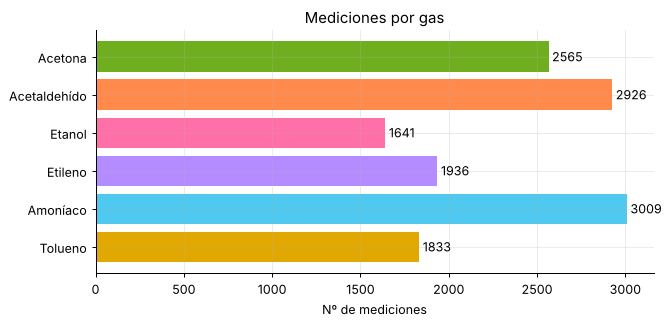

In [ ]:
por_gas = ea.mediciones_por_gas(datos)
print(por_gas.round(1).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(por_gas["gas_name"], por_gas["mediciones"], color=[COLORES_GAS[g] for g in por_gas["gas_name"]])
ax.invert_yaxis()
ax.set_xlabel("Nº de mediciones")
ax.set_title("Mediciones por gas")
for i, n in enumerate(por_gas["mediciones"]):
    ax.text(n + 20, i, str(n), va="center")
plt.show()

gas_name  Acetona  Acetaldehído  Etanol  Etileno  Amoníaco  Tolueno  total
batch                                                                     
1              90            98      83       30        70       74    445
2             164           334     100      109       532        5   1244
3             365           490     216      240       275        0   1586
4              64            43      12       30        12        0    161
5              28            40      20       46        63        0    197
6             514           574     110       29       606      467   2300
7             649           662     360      744       630      568   3613
8              30            30      40       33       143       18    294
9              61            55     100       75        78      101    470
10            600           600     600      600       600      600   3600


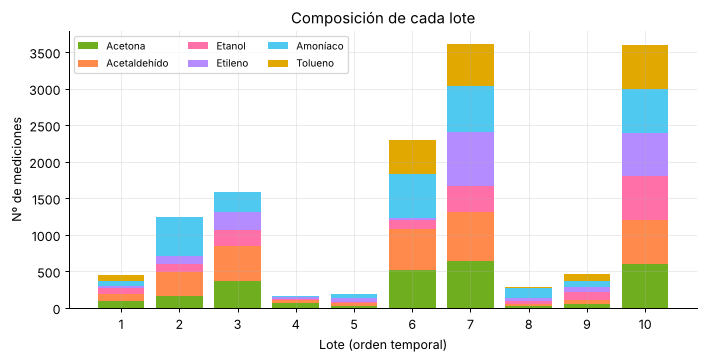

In [ ]:
lotes = ea.resumen_lotes(datos)
print(lotes.to_string())

cuentas = lotes.drop(columns="total")
fig, ax = plt.subplots(figsize=(9, 4))
base = np.zeros(len(cuentas))
for gas in cuentas.columns:
    ax.bar(cuentas.index, cuentas[gas], bottom=base, label=gas, color=COLORES_GAS[gas])
    base += cuentas[gas].to_numpy()
ax.set_xticks(cuentas.index)
ax.set_xlabel("Lote (orden temporal)")
ax.set_ylabel("Nº de mediciones")
ax.set_title("Composición de cada lote")
ax.legend(ncol=3, fontsize=8)
plt.show()

**Qué vemos:** los lotes son muy desiguales (del 4, con 161 mediciones, al 7, con 3.613) y el **tolueno no aparece en
los lotes 3, 4 y 5**. Solo el lote 10 está perfectamente equilibrado (600 mediciones de cada gas). Por tanto, al evaluar
modelos hay que mirar el macro-F1 y los resultados por gas, y no solo el accuracy.

              mediciones  niveles_distintos  minimo  mediana  maximo
gas_name                                                            
Acetona             2565                 35     2.5    100.0   600.0
Acetaldehído        2926                 38     2.5    100.0   300.0
Etanol              1641                 44     2.5    230.0  1000.0
Etileno             1936                 37     2.5    100.0   300.0
Amoníaco            3009                 47    10.0    175.0  1000.0
Tolueno             1833                 32     1.0     50.0   230.0


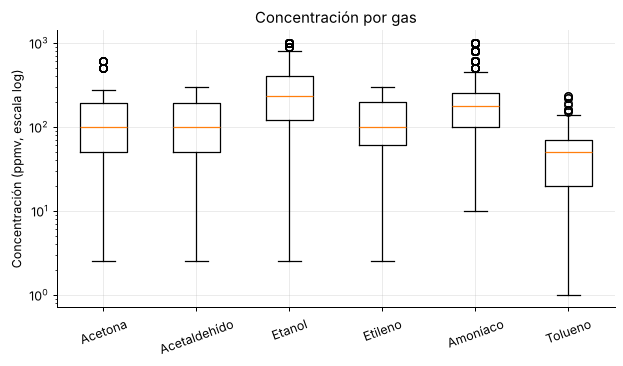

In [ ]:
print(ea.resumen_concentraciones(datos).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([datos.loc[datos["gas_name"] == g, "concentration"] for g in ORDEN_GASES])
ax.set_xticks(range(1, len(ORDEN_GASES) + 1))
ax.set_xticklabels(ORDEN_GASES, rotation=20)
ax.set_yscale("log")
ax.set_ylabel("Concentración (ppmv, escala log)")
ax.set_title("Concentración por gas")
plt.show()

La concentración va de 1 a 1.000 ppmv y cada gas se midió en 32-47 niveles distintos. Como la respuesta de un sensor
depende de la concentración, **hay que tener cuidado al comparar lotes**: si en un lote se midió a concentraciones más
altas, la señal será mayor aunque el sensor no haya cambiado.

### 2.2 Estadísticas descriptivas y forma de las variables
Las 128 variables tienen escalas muy distintas (la ΔR llega a cientos de miles; otras características valen unas pocas
unidades) y algunas son negativas (las "bajadas" de las EMA). La **asimetría** mide cuánto se alarga la cola de una
distribución: 0 es simétrica y un valor grande indica unos pocos valores muy altos.

              media  desviacion    minimo   mediana     maximo  asimetria
feature_1  50435.07    69844.79 -16757.60  19364.44  670687.35       2.55
feature_2      6.64       13.49      0.09      3.87    1339.88      70.13
feature_3     12.94       17.61      0.00      4.98     167.08       2.34
feature_6     -9.16       12.73   -131.33     -3.34      -0.01      -2.60
feature_8    -59.93      131.02  -1664.74    -14.04     115.27      -4.80

Asimetría mediana (en valor absoluto): original 2.38 -> con log firmada 0.22
Variables con asimetría > 10:          original 23 -> con log firmada 0


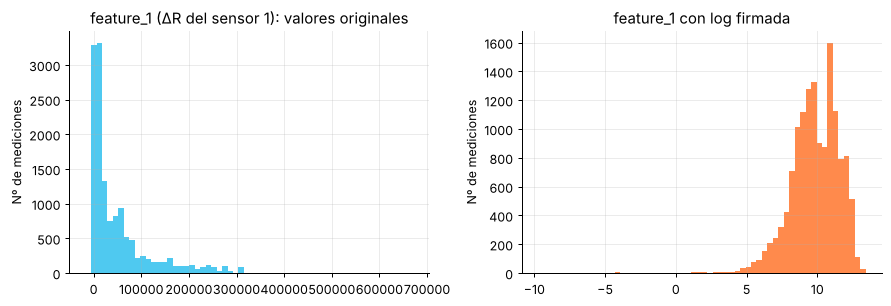

In [ ]:
estadisticas = ea.estadisticas_descriptivas(datos)
print(estadisticas.loc[["feature_1", "feature_2", "feature_3", "feature_6", "feature_8"],
                       ["media", "desviacion", "minimo", "mediana", "maximo", "asimetria"]].round(2).to_string())

X_log = log_firmada(datos[FEATURE_COLUMNS].to_numpy())
asim_original = estadisticas["asimetria"].abs()
asim_log = np.abs(__import__("pandas").DataFrame(X_log, columns=FEATURE_COLUMNS).skew())
print()
print(f"Asimetría mediana (en valor absoluto): original {asim_original.median():.2f} -> con log firmada {asim_log.median():.2f}")
print(f"Variables con asimetría > 10:          original {(asim_original > 10).sum()} -> con log firmada {(asim_log > 10).sum()}")

fig, ejes = plt.subplots(1, 2, figsize=(10, 3.5))
ejes[0].hist(datos["feature_1"], bins=60, color="#4FC9F0")
ejes[0].set_title("feature_1 (ΔR del sensor 1): valores originales")
ejes[1].hist(log_firmada(datos["feature_1"].to_numpy()), bins=60, color="#FF8A4C")
ejes[1].set_title("feature_1 con log firmada")
for eje in ejes:
    eje.set_ylabel("Nº de mediciones")
plt.tight_layout()
plt.show()

**Qué vemos:** muchas variables tienen colas larguísimas y el logaritmo con signo, `sign(x)·log(1+|x|)`, las acerca a algo
parecido a una campana sin perder el signo (un `log` normal no valdría con valores negativos). Lo usaremos en el
preprocesado (apartado 3).

### 2.3 Valores atípicos (outliers)
Usamos la regla del rango intercuartílico: un valor es atípico si queda por encima de Q3 + 1,5·IQR o por debajo de
Q1 − 1,5·IQR. **Solo los detectamos; no borramos nada.** Antes de quitar un valor hay que saber qué representa: aquí un
"atípico" puede ser simplemente una respuesta fuerte a una concentración alta, o la propia deriva.

Valores atípicos: 80397 de 1780480 (4.5%)
Mediciones con al menos una variable atípica: 35.1%
% medio de variables atípicas por lote:
{1: 7.6, 2: 9.0, 3: 6.9, 4: 10.5, 5: 8.2, 6: 0.9, 7: 1.6, 8: 0.3, 9: 0.0, 10: 7.3}


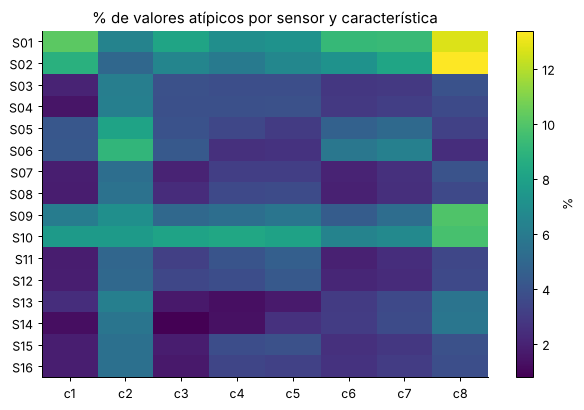

In [ ]:
por_columna, por_fila = ea.resumen_outliers(datos)
total_valores = len(datos) * len(FEATURE_COLUMNS)
print(f"Valores atípicos: {por_columna['n_atipicos'].sum()} de {total_valores} ({por_columna['n_atipicos'].sum() / total_valores:.1%})")
print(f"Mediciones con al menos una variable atípica: {(por_fila > 0).mean():.1%}")
print("% medio de variables atípicas por lote:")
print(ea.outliers_por_grupo(por_fila, datos, "batch").round(1).to_dict())

tabla = por_columna.pivot(index="sensor", columns="caracteristica", values="porcentaje")
fig, ax = plt.subplots(figsize=(8, 5))
imagen = ax.imshow(tabla, aspect="auto", cmap="viridis")
ax.set_xticks(range(8))
ax.set_xticklabels([f"c{c}" for c in tabla.columns])
ax.set_yticks(range(16))
ax.set_yticklabels([f"S{s:02d}" for s in tabla.index])
ax.set_title("% de valores atípicos por sensor y característica")
ax.grid(False)
fig.colorbar(imagen, label="%")
plt.show()

Correlación (Spearman) entre % de variables atípicas y concentración: 0.62 (cuartiles globales), 0.39 (cuartiles dentro de cada gas)


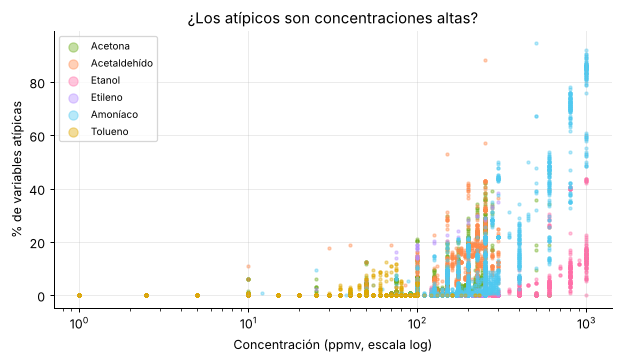

In [ ]:
r_global = por_fila.corr(datos["concentration"], method="spearman")
_, por_fila_gas = ea.resumen_outliers(datos, por_gas=True)
r_gas = por_fila_gas.corr(datos["concentration"], method="spearman")
print(f"Correlación (Spearman) entre % de variables atípicas y concentración: {r_global:.2f} (cuartiles globales), {r_gas:.2f} (cuartiles dentro de cada gas)")

fig, ax = plt.subplots(figsize=(8, 4))
for gas in ORDEN_GASES:
    filtro = datos["gas_name"] == gas
    ax.scatter(datos.loc[filtro, "concentration"], por_fila[filtro], s=6, alpha=0.4, color=COLORES_GAS[gas], label=gas)
ax.set_xscale("log")
ax.set_xlabel("Concentración (ppmv, escala log)")
ax.set_ylabel("% de variables atípicas")
ax.set_title("¿Los atípicos son concentraciones altas?")
ax.legend(markerscale=3, fontsize=8)
plt.show()

**Qué vemos:** el 35 % de las mediciones tiene alguna variable atípica, pero son solo el 4,5 % de los valores, y su
frecuencia **crece con la concentración** (correlación de Spearman de 0,62). Es decir, la mayoría no son errores sino
respuestas fuertes a concentraciones altas. Si los borráramos perderíamos justo las mediciones con más gas. Por eso
**no eliminamos ninguna fila**: tratamos las colas con la transformación log y el escalado.

### 2.4 Correlaciones y redundancia entre sensores
Para cada pareja de sensores comparamos sus 8 características y promediamos (correlación de Spearman, que compara
posiciones y no se deja engañar por los valores extremos). Si dos sensores tienen correlación cercana a 1, dicen casi
lo mismo y uno de ellos podría sobrar.

|r| >= 0.95: 28 pares redundantes; grupos: [['S02', 'S09', 'S10'], ['S03', 'S04', 'S07', 'S08', 'S11', 'S12', 'S15', 'S16'], ['S05', 'S06'], ['S13', 'S14']]
|r| >= 0.9: 34 pares redundantes; grupos: [['S02', 'S09', 'S10'], ['S03', 'S04', 'S07', 'S08', 'S11', 'S12', 'S15', 'S16'], ['S05', 'S06', 'S13', 'S14']]

  a   b  correlacion
S15 S16        0.997
S07 S08        0.997
S03 S04        0.994
S09 S10        0.991


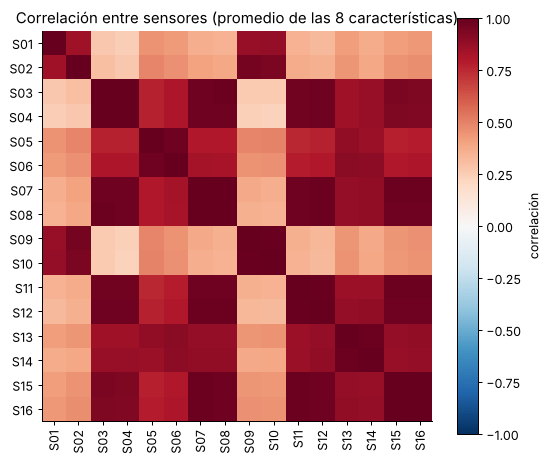

In [ ]:
redundancia = ea.redundancia_sensores(datos)

fig, ax = plt.subplots(figsize=(7, 6))
imagen = ax.imshow(redundancia, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(16))
ax.set_xticklabels(redundancia.columns, rotation=90)
ax.set_yticks(range(16))
ax.set_yticklabels(redundancia.index)
ax.set_title("Correlación entre sensores (promedio de las 8 características)")
ax.grid(False)
fig.colorbar(imagen, label="correlación")
plt.show()

for umbral in (0.95, 0.90):
    pares = ea.pares_redundantes(redundancia, umbral)
    grupos = ea.grupos_redundantes(redundancia, umbral)
    print(f"|r| >= {umbral}: {len(pares)} pares redundantes; grupos: {grupos}")
print()
print(ea.pares_redundantes(redundancia, 0.99).round(3).to_string(index=False))

**Qué vemos:** con |r| ≥ 0,95 los 16 sensores se agrupan en solo **5 familias**: S01 va solo y el resto forma los grupos
{S02, S09, S10}, {S03, S04, S07, S08, S11, S12, S15, S16}, {S05, S06} y {S13, S14}. Es una pista de que se podrían usar
menos sensores (el extra de comparar 16, 12, 8 o 4), pero **hay que comprobarlo con los modelos**: que dos sensores se
parezcan en promedio no garantiza que uno no aporte algo en el gas o el lote donde más importa.

### 2.5 PCA: ¿se ven los gases? ¿se mueven con el tiempo?
El PCA (Análisis de Componentes Principales) resume las 128 variables en unos pocos ejes que conservan la mayor parte de
la variación. Primero comprobamos si ayuda la transformación log.

sin log          PC1+PC2 = 68.6% | componentes para 90 %: 8, 95 %: 13, 99 %: 27
con log firmada  PC1+PC2 = 77.2% | componentes para 90 %: 5, 95 %: 9, 99 %: 23


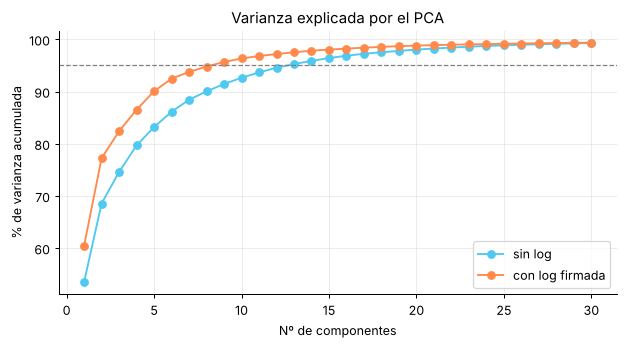

In [ ]:
con_log = ea.varianza_explicada(datos, 128, transformar_log=True)
sin_log = ea.varianza_explicada(datos, 128, transformar_log=False)

def componentes_para(tabla, objetivo):
    return int((tabla["acumulada"] < objetivo).sum() + 1)

for nombre, tabla in (("sin log", sin_log), ("con log firmada", con_log)):
    print(f"{nombre:16s} PC1+PC2 = {tabla['acumulada'][1]:.1%} | componentes para 90 %: {componentes_para(tabla, 0.90)}, "
          f"95 %: {componentes_para(tabla, 0.95)}, 99 %: {componentes_para(tabla, 0.99)}")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(sin_log["componente"][:30], sin_log["acumulada"][:30] * 100, "o-", label="sin log", color="#4FC9F0")
ax.plot(con_log["componente"][:30], con_log["acumulada"][:30] * 100, "o-", label="con log firmada", color="#FF8A4C")
ax.axhline(95, color="gray", ls="--", lw=1)
ax.set_xlabel("Nº de componentes")
ax.set_ylabel("% de varianza acumulada")
ax.set_title("Varianza explicada por el PCA")
ax.legend()
plt.show()

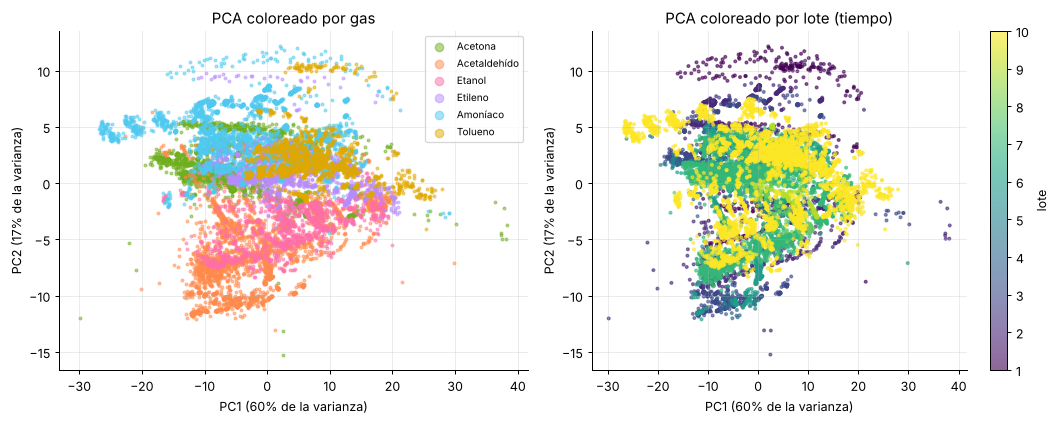

In [ ]:
coords, info = ea.pca_proyeccion(datos, n_componentes=2, transformar_log=True)
v = info["varianza_explicada"]

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.8))
for gas in ORDEN_GASES:
    filtro = coords["gas_name"] == gas
    ejes[0].scatter(coords.loc[filtro, "PC1"], coords.loc[filtro, "PC2"], s=5, alpha=0.5, color=COLORES_GAS[gas], label=gas)
ejes[0].set_title("PCA coloreado por gas")
ejes[0].legend(markerscale=3, fontsize=8)
puntos = ejes[1].scatter(coords["PC1"], coords["PC2"], c=coords["batch"], s=5, alpha=0.6, cmap="viridis")
ejes[1].set_title("PCA coloreado por lote (tiempo)")
fig.colorbar(puntos, ax=ejes[1], label="lote")
for eje in ejes:
    eje.set_xlabel(f"PC1 ({v[0]:.0%} de la varianza)")
    eje.set_ylabel(f"PC2 ({v[1]:.0%} de la varianza)")
plt.tight_layout()
plt.show()

**Qué vemos:** con la transformación log hacen falta 9 componentes para el 95 % de la información (13 sin ella) y los dos
primeros ya resumen el 77 %. A la izquierda algunos gases se separan (el acetaldehído y el etanol quedan abajo) pero otros se
solapan mucho: **dos componentes no bastan para distinguir los seis gases**, para eso están los modelos. A la derecha, los
lotes no se reparten por igual por la nube: **el mismo gas no está siempre en el mismo sitio**. Para verlo con más claridad,
ajustamos el PCA **solo con los lotes 1 y 2** (como si fueran los datos "de entrenamiento") y proyectamos los demás sobre él:
si el centro de cada gas se aleja de donde estaba, las mediciones nuevas ya no se parecen a las que conocía el modelo.

Distancia del centro de cada gas al que tenía en el lote 1 (unidades del PCA):
gas_name  Acetaldehído  Acetona  Amoníaco  Etanol  Etileno  Tolueno
batch                                                              
1                  0.0      0.0       0.0     0.0      0.0      0.0
2                  5.0      3.1       4.7     0.9      6.2      3.3
3                  9.3     11.6       4.2     4.5      6.0      NaN
4                  9.4     13.8      11.8     1.8      7.6      NaN
5                  9.9     15.0      10.7     2.8     11.2      NaN
6                  3.6      7.2       4.8     0.6      9.4      8.8
7                  5.2      8.4       7.4     4.3      6.3      8.0
8                  7.1      6.0       8.8     2.9      7.3      8.4
9                  9.2      5.3       6.3     5.5      5.6     10.0
10                 2.5      1.3      11.4     2.3      7.8      6.0


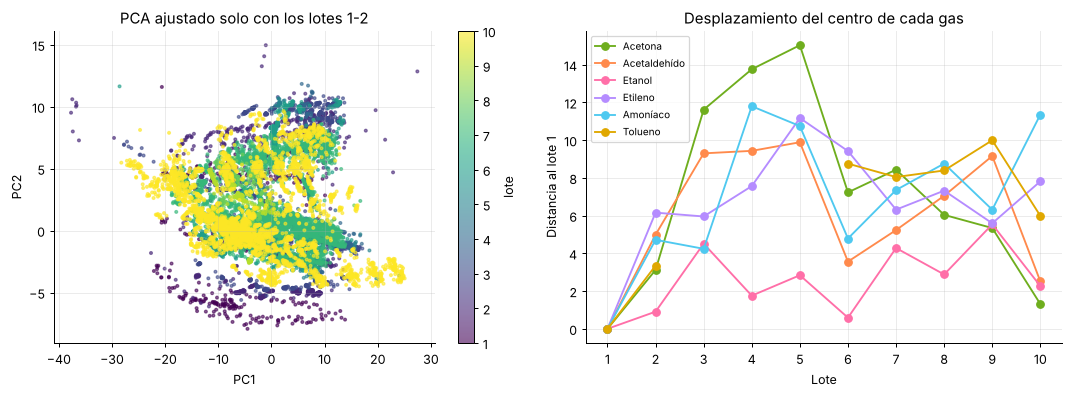

In [ ]:
coords_12, info_12 = ea.pca_proyeccion(datos, n_componentes=2, lotes_ajuste=[1, 2])
deriva = ea.deriva_pca(coords_12, referencia=1)
tabla_deriva = deriva.pivot(index="batch", columns="gas_name", values="distancia")
print("Distancia del centro de cada gas al que tenía en el lote 1 (unidades del PCA):")
print(tabla_deriva.round(1).to_string())

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
puntos = ejes[0].scatter(coords_12["PC1"], coords_12["PC2"], c=coords_12["batch"], s=5, alpha=0.6, cmap="viridis")
ejes[0].set_title("PCA ajustado solo con los lotes 1-2")
ejes[0].set_xlabel("PC1")
ejes[0].set_ylabel("PC2")
fig.colorbar(puntos, ax=ejes[0], label="lote")
for gas in ORDEN_GASES:
    if gas in tabla_deriva:
        ejes[1].plot(tabla_deriva.index, tabla_deriva[gas], "o-", color=COLORES_GAS[gas], label=gas)
ejes[1].set_xticks(range(1, 11))
ejes[1].set_xlabel("Lote")
ejes[1].set_ylabel("Distancia al lote 1")
ejes[1].set_title("Desplazamiento del centro de cada gas")
ejes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Qué vemos:** respecto al lote 1, el centro de cada gas se aleja en promedio unas 4 unidades en el lote 2 y casi 10 en
el lote 5, y aunque después baja algo no vuelve a cero. **Cuidado al interpretarlo:** esta distancia mezcla deriva real con
cambios de concentración y de mezcla de gases entre lotes. Es una señal de que la deriva existe, no una medida pura de ella.

### 2.6 Deriva por sensor: ¿qué sensores cambian?
Para un gas y un rango de concentración fijos, comparamos la respuesta mediana de cada sensor en cada lote con la del
lote 1: `log2(mediana del lote / mediana del lote 1)` (0 = igual, +1 = el doble, −1 = la mitad). Al fijar el rango de
concentración (50-150 ppmv) comparamos de forma más justa.

Mediciones de acetona entre 50 y 150 ppmv por lote: {1: 32, 2: 57, 3: 168, 4: 28, 5: 12, 6: 440, 7: 264, 10: 300}
Mayor cambio: sensor S10 en el lote 4 (-5.31 -> 39.7 veces)


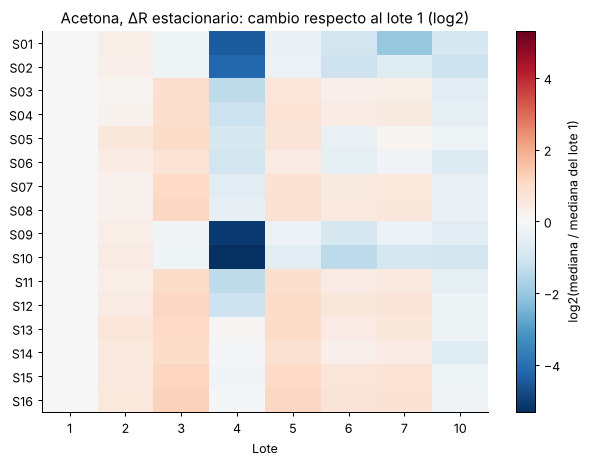

In [ ]:
matriz = ea.deriva_por_sensor(datos, gas="Acetona", caracteristica=1, referencia=1, rango_concentracion=(50, 150))
print("Mediciones de acetona entre 50 y 150 ppmv por lote:",
      datos[(datos["gas_name"] == "Acetona") & datos["concentration"].between(50, 150)].groupby("batch").size().to_dict())

limite = np.nanmax(np.abs(matriz.to_numpy()))
fig, ax = plt.subplots(figsize=(8, 5.5))
imagen = ax.imshow(matriz, aspect="auto", cmap="RdBu_r", vmin=-limite, vmax=limite)
ax.set_xticks(range(len(matriz.columns)))
ax.set_xticklabels(matriz.columns)
ax.set_yticks(range(len(matriz.index)))
ax.set_yticklabels(matriz.index)
ax.set_xlabel("Lote")
ax.set_title("Acetona, ΔR estacionario: cambio respecto al lote 1 (log2)")
ax.grid(False)
fig.colorbar(imagen, label="log2(mediana / mediana del lote 1)")
plt.show()

mayor = matriz.drop(columns=1).abs().stack().idxmax()
print(f"Mayor cambio: sensor {mayor[0]} en el lote {mayor[1]} ({matriz.loc[mayor]:+.2f} -> {2 ** abs(matriz.loc[mayor]):.1f} veces)")

**Qué vemos:** la respuesta de los sensores cambia con los lotes y **no todos cambian igual**. En el lote 4, S01, S02, S09 y
S10 (los mismos que en el apartado 2.7 salen como los más importantes) responden entre unas 18 y 40 veces menos que en el
lote 1, mientras que S13 a S16 apenas cambian y el resto se mueve entre la mitad y el doble. Esto es justo lo que un modelo
entrenado con los primeros lotes no ha visto. Con pocas mediciones en algunos lotes (el 4 y el 5 tienen 28 y 12 de acetona
en ese rango) conviene no sobreinterpretar un lote concreto.

### 2.7 Importancia de cada sensor
¿Qué sensores separan mejor los gases? Calculamos el estadístico F de ANOVA de cada variable (cuánto se separan las
medias de los gases frente a lo que varían dentro de cada gas) y lo resumimos por sensor. **Solo con los lotes 1 a 3** (que
actuarían de entrenamiento): si calculáramos el ranking con todos los lotes, se colaría información del futuro.

etiqueta  puntuacion_relativa
     S01                 1.00
     S02                 0.96
     S09                 0.94
     S10                 0.92
     S15                 0.13
     S11                 0.12
     S16                 0.12
     S07                 0.11
Sensor más importante en cada lote: {1: 'S01', 2: 'S01', 3: 'S10', 4: 'S01', 5: 'S10', 6: 'S09', 7: 'S09', 8: 'S09', 9: 'S09', 10: 'S09'}


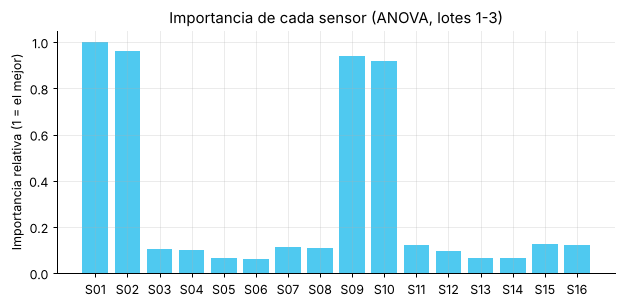

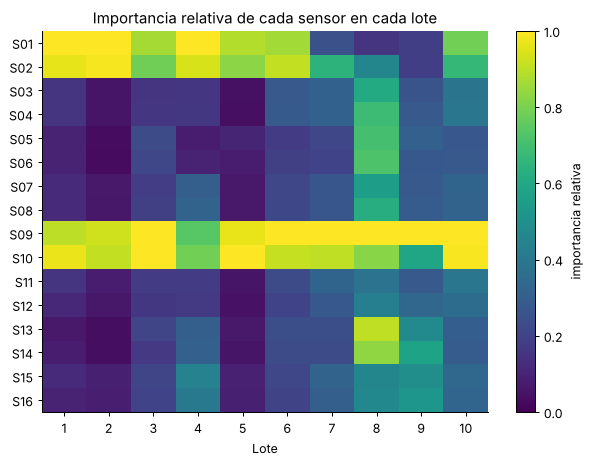

In [ ]:
ranking = ea.importancia_sensores(datos, metodo="anova", lotes=[1, 2, 3])
print(ranking.sort_values("puntuacion", ascending=False)[["etiqueta", "puntuacion_relativa"]].round(2).head(8).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(ranking["etiqueta"], ranking["puntuacion_relativa"], color="#4FC9F0")
ax.set_ylabel("Importancia relativa (1 = el mejor)")
ax.set_title("Importancia de cada sensor (ANOVA, lotes 1-3)")
plt.show()

por_lote = ea.importancia_por_lote(datos)
fig, ax = plt.subplots(figsize=(8, 5.5))
imagen = ax.imshow(por_lote, aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(por_lote.columns)))
ax.set_xticklabels(por_lote.columns)
ax.set_yticks(range(len(por_lote.index)))
ax.set_yticklabels(por_lote.index)
ax.set_xlabel("Lote")
ax.set_title("Importancia relativa de cada sensor en cada lote")
ax.grid(False)
fig.colorbar(imagen, label="importancia relativa")
plt.show()
print("Sensor más importante en cada lote:", por_lote.idxmax().to_dict())

**Qué vemos:** con los lotes 1-3 destacan cuatro sensores (S01, S02, S09 y S10) y el resto queda muy por debajo. Pero
**el mejor sensor cambia con el tiempo**: S01 en los lotes 1, 2 y 4, S10 en el 3 y el 5, y S09 del 6 al 10. Una selección de
sensores hecha una sola vez con lotes antiguos puede dejar de ser la mejor, otra consecuencia de la deriva. Además, S02,
S09 y S10 son del mismo grupo redundante (apartado 2.4), así que no hace falta quedarse con los tres.

### 2.8 Resumen de hallazgos
- **Calidad:** 13.910 mediciones, 128 variables, sin nulos ni duplicados. Pero los lotes son muy desiguales y el tolueno falta en los lotes 3, 4 y 5.
- **Forma de las variables:** colas muy largas (asimetría mediana 2,38; 23 variables por encima de 10) que la transformación log firmada reduce (0,22 y ninguna).
- **Atípicos:** son frecuentes pero ligados a la concentración (r = 0,62); no se eliminan.
- **Redundancia:** los 16 sensores se reducen a 5 familias con |r| ≥ 0,95.
- **PCA:** los gases forman grupos, pero se desplazan con los lotes: señal de deriva (mezclada con cambios de concentración y de mezcla de gases).
- **Sensores:** no todos derivan igual y el ranking de importancia cambia con el tiempo.

## 3. Preprocesado
Responsable: Persona 1

Decisiones que se desprenden del análisis anterior (las funciones están en `src/preprocessing.py`):

| Decisión | Por qué |
|---|---|
| **No se elimina ninguna fila** | Los atípicos están ligados a la concentración y pueden ser la propia deriva (apartado 2.3). |
| **Transformación log firmada** `sign(x)·log(1+|x|)` | Reduce las colas largas y mantiene el signo de las variables negativas (apartado 2.2). |
| **`StandardScaler`** después del log | Cada variable tiene una escala distinta; sin escalar, la ΔR dominaría. |
| **Se ajusta solo con los lotes de entrenamiento** | Si el escalado "viera" lotes futuros, se filtraría información del futuro. |
| **División por lotes, nunca aleatoria** | Mezclar lotes antiguos y recientes taparía la deriva. `dividir_por_lotes` avisa si se entrena con el futuro. |
| **Selección de sensores opcional** | La redundancia (2.4) y la importancia (2.7) apuntan a que sobran sensores, pero hay que comprobarlo con los modelos. |

`crear_preprocesador()` devuelve un `Pipeline` de scikit-learn (log + escalado) pensado como **primer bloque del Pipeline
completo**, para que la API de BentoML aplique exactamente el mismo preprocesado que el entrenamiento.

In [ ]:
from src.preprocessing import crear_preprocesador, dividir_por_lotes, separar_xy, seleccionar_sensores

LOTES_TRAIN = [1, 2, 3]
LOTES_TEST = [4, 5, 6, 7, 8, 9, 10]
train, test = dividir_por_lotes(datos, LOTES_TRAIN, LOTES_TEST)
print(f"train: {len(train)} mediciones (lotes {LOTES_TRAIN}) | test: {len(test)} mediciones (lotes {LOTES_TEST[0]}-{LOTES_TEST[-1]})")

# Un error a propósito: entrenar con el lote 5 y evaluar con el 4 es usar el futuro
try:
    dividir_por_lotes(datos, [5], [4])
except ValueError as error:
    print("Aviso correcto ->", error)

preproceso = crear_preprocesador(transformar_log=True).fit(train[FEATURE_COLUMNS])
Z_train = preproceso.transform(train[FEATURE_COLUMNS])
Z_test = preproceso.transform(test[FEATURE_COLUMNS])
print(f"Forma: train {Z_train.shape}, test {Z_test.shape} (128 variables entran y 128 salen)")
print(f"Train: media {Z_train.mean():+.3f}, desviación {Z_train.std():.3f}  (0 y 1 por construcción)")
print(f"Test:  media {Z_test.mean():+.3f}, desviación {Z_test.std():.3f}  (no son 0 y 1: el escalado no ha visto estos lotes)")

train: 3275 mediciones (lotes [1, 2, 3]) | test: 10635 mediciones (lotes 4-10)
Aviso correcto -> Fuga temporal: se entrena con el lote 5 y se evalúa con el lote 4, que es anterior. Usa permitir_futuro=True solo si es a propósito.
Forma: train (3275, 128), test (10635, 128) (128 variables entran y 128 salen)
Train: media -0.000, desviación 1.000  (0 y 1 por construcción)
Test:  media -0.106, desviación 1.032  (no son 0 y 1: el escalado no ha visto estos lotes)


Cómo se usaría en el entrenamiento (lo hace la Persona 2 en `src/training.py`): el preprocesador va **dentro** del
`Pipeline`, así se ajusta solo con los datos de entrenamiento y se guarda junto al modelo.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

X_train, y_train = separar_xy(train)
X_test, y_test = separar_xy(test)

modelo_de_ejemplo = Pipeline([
    ("preproceso", crear_preprocesador(transformar_log=True)),
    ("modelo", LogisticRegression(max_iter=2000)),
])
modelo_de_ejemplo.fit(X_train, y_train)
print("El Pipeline completo se entrena y predice:", modelo_de_ejemplo.predict(X_test.head(5)))
print("(Solo es una comprobación de que encaja: las métricas y la comparación de modelos son de la Persona 2.)")

El Pipeline completo se entrena y predice: [5 1 1 1 1]
(Solo es una comprobación de que encaja: las métricas y la comparación de modelos son de la Persona 2.)


Y si se quisiera reducir el número de sensores (extra: 16, 12, 8 o 4), el ranking se calcula **solo con los lotes de
entrenamiento** y se convierte en una lista de columnas:

In [ ]:
ranking_train = ea.importancia_sensores(train, metodo="anova")   # solo con los lotes de entrenamiento
columnas_8 = seleccionar_sensores(ranking_train, 8)
X_train_8, _ = separar_xy(train, columnas_8)
print(f"8 sensores elegidos: {sorted(ranking_train.sort_values('puntuacion', ascending=False).head(8)['etiqueta'])}")
print(f"X con 8 sensores: {X_train_8.shape} (8 sensores x 8 características = 64 variables)")

8 sensores elegidos: ['S01', 'S02', 'S07', 'S09', 'S10', 'S11', 'S15', 'S16']
X con 8 sensores: (3275, 64) (8 sensores x 8 características = 64 variables)


Ojo: el ranking mira cada sensor por separado, así que entre los 8 elegidos hay sensores de la **misma familia redundante**
(S07, S11, S15 y S16 son del grupo grande del apartado 2.4). Si el objetivo es reducir sensores, una opción más sensata es
quedarse con uno o dos de cada familia y comprobar con los modelos que no se pierde rendimiento.

**Qué se entrega al resto del equipo**

- `data/processed/gas_drift.parquet`: tabla limpia (`batch`, `gas`, `gas_name`, `concentration`, `feature_1..128`).
- `separar_xy`, `dividir_por_lotes`, `crear_preprocesador` y `seleccionar_sensores` (`src/preprocessing.py`) para entrenar sin fugas temporales.
- `src/exploratory_analysis.py` y `src/eda_plots.py`: cálculos y gráficos del análisis, usados por las cinco pestañas nuevas de *Sensor Explorer*.

## 4. Modelos base (E1)
Responsable: Persona 2

### 4.1 Cómo medimos los modelos
Se usan dos métricas generales: la accuracy (porcentaje de aciertos) y el F1 macro (la media del F1 de cada gas, todos
con el mismo peso). Como se vio en el EDA, los gases están desbalanceados, así que la accuracy sola puede esconder que
un gas falla mucho.

El F1 macro de un lote se calcula solo con los gases presentes en ese lote. El tolueno no aparece en los lotes 3, 4 y 5,
así que ahí no se puede medir lo bien que se reconoce y no tiene sentido ponerle un cero. Si el modelo predice tolueno
donde no lo hay, el fallo sigue contando porque baja el recall del gas real. Eso sí, al comparar lotes hay que tener en
cuenta que en unos se promedian 5 gases y en otros 6.

La matriz de confusión es siempre de 6×6 (filas con el gas real, columnas con el predicho, códigos del 1 al 6). Para
comprobar el criterio a mano se usa un ejemplo inventado.

In [22]:
from src.evaluation import calcular_metricas

y_real = [1, 1, 2, 2] #ejemplo inventado, solo con los gases 1 y 2
y_pred = [1, 6, 2, 2] #una muestra del gas 1 sale como tolueno (6)

metricas = calcular_metricas(y_real, y_pred)

print("Accuracy:  ", metricas["accuracy"])
print("F1 por gas:", metricas["f1_por_gas"])
print("Macro-F1:  ", metricas["macro_f1"])
print("Matriz de confusión:")
for fila in metricas["matriz_confusion"]:
    print(fila)

Accuracy:   0.75
F1 por gas: {1: 0.6666666666666666, 2: 1.0}
Macro-F1:   0.8333333333333333
Matriz de confusión:
[1, 0, 0, 0, 0, 1]
[0, 2, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 0]


### 4.2 Entrenar un modelo
La función entrenar(datos, config) recibe la tabla limpia y un diccionario con el modelo, sus parámetros y los lotes.
Separa train y test por lotes (nunca al azar, igual que en la sección 3) y mete el preprocesado dentro del pipeline,
así que solo aprende de los lotes de train. Devuelve el pipeline ya entrenado y las métricas en test.

In [23]:
from src.training import entrenar

config = {
    "modelo": "logreg", #"logreg", "rf" o "svm"
    "params": {}, #parametros del modelo que se quieran cambiar
    "lotes_train": [1, 2, 3],
    "lotes_test": [4],
}
pipeline, metricas = entrenar(datos, config)

print(pipeline)
print()
for clave, valor in metricas.items():
    print(clave, "->", valor)

Pipeline(steps=[('preproceso',
                 Pipeline(steps=[('log_firmada',
                                  FunctionTransformer(func=<function log_firmada at 0x00000240EF3B1760>)),
                                 ('escalado', StandardScaler())])),
                ('modelo', LogisticRegression(max_iter=2000, random_state=42))])

accuracy -> 0.7888198757763976
macro_f1 -> 0.7949579831932773
f1_por_gas -> {1: 0.7619047619047619, 2: 1.0, 3: 1.0, 4: 0.7843137254901961, 5: 0.42857142857142855}
matriz_confusion -> [[40, 0, 0, 1, 23, 0], [0, 43, 0, 0, 0, 0], [0, 0, 12, 0, 0, 0], [1, 0, 0, 20, 9, 0], [0, 0, 0, 0, 12, 0], [0, 0, 0, 0, 0, 0]]
n_train -> 3275
n_test -> 161
train_batches -> [1, 2, 3]
test_batches -> [4]


### 4.3 Comparación de modelos (E1)
Se comparan regresión logística, Random Forest y SVM con sus parámetros de partida (en la regresión logística solo se
sube max_iter). Los tres se entrenan con los lotes 1 a 3 y se evalúan en el lote 4, con el mismo preprocesado, para que
la comparación sea justa. La idea de recorrer varios modelos en un bucle es la misma que en el Laboratorio 5, pero aquí
la división es por lotes en lugar de aleatoria.

In [ ]:
import pandas as pd

from src.training import entrenar

nombres = {"logreg": "Regresión logística", "rf": "Random Forest", "svm": "SVM"}
resultados_e1 = {} #aqui se guardan las metricas de cada modelo
filas = []

for modelo in nombres:
    config = {"modelo": modelo, "params": {}, "lotes_train": [1, 2, 3], "lotes_test": [4]}
    _, metricas = entrenar(datos, config)
    resultados_e1[modelo] = metricas
    filas.append([nombres[modelo], metricas["accuracy"], metricas["macro_f1"]])

tabla_e1 = pd.DataFrame(filas, columns=["modelo", "accuracy", "macro_f1"])
print(tabla_e1.round(3).to_string(index=False))

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
import numpy as np

from src.contracts import GAS_NAMES

nombres_gases = [] #en el orden de los codigos, 1 a 6
for codigo_gas in sorted(GAS_NAMES):
    nombres_gases.append(GAS_NAMES[codigo_gas])

fig, ejes = plt.subplots(1, 3, figsize=(18, 5))
posicion = 0
for modelo in nombres:
    matriz = np.array(resultados_e1[modelo]["matriz_confusion"])
    grafica = ConfusionMatrixDisplay(matriz, display_labels=nombres_gases)
    grafica.plot(ax=ejes[posicion], cmap="Blues", colorbar=False, xticks_rotation=45)
    ejes[posicion].set_title(nombres[modelo])
    ejes[posicion].set_xlabel("Gas predicho")
    ejes[posicion].set_ylabel("Gas real")
    ejes[posicion].grid(False)
    posicion = posicion + 1
plt.tight_layout()
plt.show()

El SVM es el que tiene mejor F1 macro (0,874), por delante del Random Forest (0,825) y de la regresión logística
(0,795). En accuracy gana el Random Forest (0,839 frente a 0,820 del SVM), pero esa diferencia son solo 3 mediciones.

Cada modelo falla en un sitio distinto:

- La regresión logística predice amoníaco cuando no lo es: 23 mediciones de acetona y 9 de etileno. Por eso el F1 del
amoníaco se queda en 0,429, aunque acierta las 12 que sí son de amoníaco.
- El Random Forest confunde 22 de las 30 mediciones de etileno con acetona (F1 del etileno de 0,410). Como la acetona
la acierta casi siempre y es el gas con más mediciones del lote, su accuracy sale alta, pero el F1 macro lo penaliza.
- El SVM confunde 18 mediciones de acetona con acetaldehído y 10 de etileno con acetona.

Ninguno predice tolueno en este lote.

Nos quedamos con el SVM para las secciones siguientes porque tiene el mejor F1 macro, que es la métrica que trata igual
a todos los gases. Aun así, el lote 4 solo tiene 161 mediciones (12 de etanol y 12 de amoníaco), así que no se puede
decir que un modelo sea claramente mejor. Además, como el lote 4 se ha usado para elegir, el resultado del SVM en ese
lote puede ser algo optimista.

## 5. Deriva temporal (E2)
Responsable: Persona 2

En la sección 2 se vio que los datos cambian de un lote a otro. Aquí se mide cuánto afecta eso a un modelo que no se
vuelve a entrenar: se entrena el SVM una sola vez con los lotes 1 a 3 y se evalúa por separado en cada lote del 4 al 10.

La función evolucion_por_lote calcula a la vez este modelo fijo y el reentrenado de la sección 6, así que se ejecuta
una vez y aquí solo se mira la parte del fijo.

In [ ]:
from src.drift_analysis import evolucion_por_lote

config_deriva = {
    "modelo": "svm", #el elegido en E1
    "params": {},
    "lotes_train": [1, 2, 3],
    "lotes_test": [4, 5, 6, 7, 8, 9, 10],
}
tabla_deriva = evolucion_por_lote(datos, config_deriva)

fijo = tabla_deriva[tabla_deriva["estrategia"] == "fijo"]
print(fijo.round(3).to_string(index=False))

In [ ]:
filas = []
for lote in range(1, 11):
    datos_lote = datos[datos["batch"] == lote]
    filas.append([lote, len(datos_lote), datos_lote["gas"].nunique(), datos_lote["concentration"].median()])

contexto = pd.DataFrame(filas, columns=["lote", "mediciones", "gases", "concentracion_mediana"]) #para no achacarlo todo a la deriva
print(contexto.to_string(index=False))

In [ ]:
plt.figure(figsize=(9, 4))
plt.plot(fijo["lote"], fijo["accuracy"], "o-", label="accuracy")
plt.plot(fijo["lote"], fijo["macro_f1"], "s--", label="F1 macro")
plt.ylim(0, 1.05)
plt.xlabel("Lote evaluado")
plt.title("E2: SVM entrenado una sola vez con los lotes 1 a 3")
plt.legend()
plt.show()

El modelo fijo va bien en los lotes 4 y 5 (F1 macro de 0,874 y 0,979), pero desde el lote 6 empeora. En el 6 y el 7 se
queda en 0,639 y 0,651, y en el 8 cae a 0,362 (accuracy de 0,340). En los lotes 9 y 10 sigue bajo, con 0,488 y 0,433.

La caída no es continua: el lote 5 sale mejor que el 4 aunque es posterior, y el 9 mejor que el 8. Además, no se puede
atribuir todo a la deriva, porque de un lote a otro cambian a la vez otras cosas:

- Desde el lote 6 vuelve a haber tolueno. El modelo solo lo ha visto en los lotes 1 y 2, y a partir de aquí el F1 macro
promedia 6 gases en lugar de 5.
- La mezcla cambia mucho: en el lote 8 casi la mitad de las mediciones son de amoníaco y en el 6 el etileno es solo el 1%.
- La concentración mediana cambia entre lotes (50 ppmv en el 6 y 200 en el 5).
- Los lotes 4, 5 y 8 son pequeños (161, 197 y 294 mediciones), así que sus resultados son menos fiables.

Lo que sí se puede decir es que un modelo entrenado solo con los primeros lotes deja de ser fiable en los últimos.

## 6. Reentrenamiento periódico (E3)
Responsable: Persona 2

Ahora se compara el modelo fijo con uno que se reentrena antes de cada lote usando todos los lotes anteriores. Por
ejemplo, para evaluar el lote 7 se entrena con los lotes 1 a 6. Nunca se entrena con el lote que se evalúa ni con
lotes posteriores. En la práctica, esto supone que ya se conoce el gas real de las mediciones anteriores.

In [ ]:
comparacion = tabla_deriva.pivot(index="lote", columns="estrategia", values=["accuracy", "macro_f1"])
print(comparacion.round(3).to_string())

print()
print("Media de los lotes 5 a 10 (en el 4 las dos estrategias son iguales):")
posteriores = tabla_deriva[tabla_deriva["lote"] >= 5]
print(posteriores.groupby("estrategia")[["accuracy", "macro_f1"]].mean().round(3).to_string())

In [ ]:
reentrenado = tabla_deriva[tabla_deriva["estrategia"] == "reentrenado"]
metricas_grafica = ["accuracy", "macro_f1"]
titulos = ["Accuracy", "F1 macro"]

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
for i in range(2):
    ejes[i].plot(fijo["lote"], fijo[metricas_grafica[i]], "o-", label="fijo")
    ejes[i].plot(reentrenado["lote"], reentrenado[metricas_grafica[i]], "s-", label="reentrenado")
    ejes[i].set_ylim(0, 1.05)
    ejes[i].set_xlabel("Lote evaluado")
    ejes[i].set_title(titulos[i])
    ejes[i].legend()
plt.tight_layout()
plt.show()

De media en los lotes 5 a 10, reentrenar sube el F1 macro de 0,592 a 0,799 y la accuracy de 0,629 a 0,819 (media
simple, cada lote cuenta lo mismo). La mejora no es igual en todos:

- En los lotes 5 y 6 casi no hay diferencia (en el 6, 0,639 frente a 0,641 de F1 macro).
- En el 7 sube de 0,651 a 0,794.
- El lote 8 es el que más mejora, de 0,362 a 0,948.
- En los lotes 9 y 10 sube de 0,488 a 0,743 y de 0,433 a 0,694.

Es decir, reentrenar recupera buena parte del rendimiento, pero no siempre todo. En el lote 10 el F1 macro se queda en
0,694 aunque se ha entrenado con los nueve lotes anteriores.

En cada lote las dos estrategias se evalúan con las mismas mediciones, así que la diferencia entre ellas no se debe a la
mezcla de ese lote. Eso sí, el reentrenado tiene datos más recientes y además muchos más datos (con los lotes 1 a 9 son
10.310 mediciones frente a 3.275), así que con este experimento no se puede separar cuál de las dos cosas ayuda más.

### 6.1 ¿Pasa lo mismo con los otros modelos?
Para comprobar que la conclusión no depende de haber elegido el SVM, se repite la comparación con los otros dos.

In [ ]:
for modelo in ["logreg", "rf"]:
    config_otro = {"modelo": modelo, "params": {}, "lotes_train": [1, 2, 3], "lotes_test": [4, 5, 6, 7, 8, 9, 10]}
    tabla_otro = evolucion_por_lote(datos, config_otro)
    print(nombres[modelo], "(F1 macro por lote)")
    print(tabla_otro.pivot(index="lote", columns="estrategia", values="macro_f1").round(3).to_string())
    posteriores = tabla_otro[tabla_otro["lote"] >= 5]
    print("Media de los lotes 5 a 10:")
    print(posteriores.groupby("estrategia")["macro_f1"].mean().round(3).to_string())
    print()

Con los otros dos modelos la conclusión general se mantiene. De media en los lotes 5 a 10, el F1 macro pasa de 0,589 a
0,785 en la regresión logística y de 0,469 a 0,751 en el Random Forest. En los lotes 7 a 10 el reentrenado es mejor con
los tres modelos.

En los lotes 5 y 6 depende más del modelo: el Random Forest mejora bastante en el 5 (de 0,721 a 0,909), mientras que la
regresión logística queda algo peor al reentrenar en el 6 (0,647 frente a 0,630). Por eso no se puede decir que
reentrenar ayude siempre.

### 6.2 Modelo final
El modelo que usará la API es el SVM entrenado con los lotes 1 a 9. Se deja fuera el lote 10 para tener todavía una
evaluación con datos que el modelo no ha visto. Se guarda el pipeline completo, así que la API le pasa las 128 features
sin escalar.

In [ ]:
from src.training import cargar_modelo, guardar_modelo

config_final = {"modelo": "svm", "params": {}, "lotes_train": [1, 2, 3, 4, 5, 6, 7, 8, 9], "lotes_test": [10]}
modelo_final, metricas_final = entrenar(datos, config_final)
ruta = guardar_modelo(modelo_final)

print("Modelo guardado en", ruta.name)
print("Accuracy en el lote 10:", round(metricas_final["accuracy"], 3))
print("F1 macro en el lote 10:", round(metricas_final["macro_f1"], 3))

recargado = cargar_modelo()
medicion = datos[datos["batch"] == 10].iloc[0]
features = medicion[FEATURE_COLUMNS].tolist() #igual que lo mandara la api, una lista de 128 numeros
print("Gas real:", medicion["gas"], "| gas predicho:", recargado.predict([features])[0])

En el lote 10 el modelo final tiene una accuracy de 0,693 y un F1 macro de 0,694, que es el mismo resultado que el
reentrenado en ese lote. Es bastante mejor que el modelo fijo (0,433 de F1 macro), pero sigue fallando en cerca de 3 de
cada 10 mediciones, así que sus predicciones hay que tomarlas con cuidado.
De hecho, la medición de ejemplo (la primera del lote 10) falla: es etileno y la predice como tolueno.

Quedan cosas por probar: ajustar los parámetros (siempre validando con lotes anteriores al de test), reentrenar solo
con los lotes más recientes para separar el efecto de tener más datos del de que sean recientes, y añadir un indicador
de cambio de distribución que avise de cuándo conviene reentrenar.

## 7. Conclusiones
Responsable: todo el equipo